## Лабораторная работа №1 | Вариант 6

Выполнил: 

Кириенко Анастасия Ивановна М8О-314БВ-24

### 1. Numpy

In [96]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [97]:
matrix_1 = np.eye(3)
print(matrix)

<class 'numpy.matrix'>


2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [98]:
matrix_2 = np.diag([1, 2, 3, 4], -1)
print(matrix_2)

[[0 0 0 0 0]
 [1 0 0 0 0]
 [0 2 0 0 0]
 [0 0 3 0 0]
 [0 0 0 4 0]]


3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

In [99]:
print(sum(range(5), -1))
from numpy import *
print(sum(range(5), -1))

10
10


В первом случае 9, тк используется стандартная функция sum()
Во втором случае будет 10, тк используется функция sum() из библиотеки numpy

4. Как найти самое часто встречаемое значение между двумя массивами? 

In [100]:
a = np.array([1, 2, 3, 4, 5])
b = np.array([1, 2, 3, 4, 4, 5, 5, 4])
unique_elements = np.intersect1d(a, b)
counts = np.bincount(np.concatenate((a, b)))[unique_elements]
print(unique_elements[np.argmax(counts)])

4


5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [101]:
import warnings

warnings.filterwarnings('ignore', module='numpy')

6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [102]:
def generator_numbers():
    for i in range(10):
        yield i

arr_generator = np.array(list(generator_numbers()))
print(arr_generator)

[0 1 2 3 4 5 6 7 8 9]


7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [103]:
arr_random = np.random.rand(10)
sorted_arr = np.sort(arr_random)
print(sorted_arr)

[0.06602543 0.26689432 0.33318674 0.33705693 0.51703834 0.5284067
 0.84598847 0.85024724 0.8788778  0.922962  ]


8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [104]:
coordinates = np.random.rand(10, 2)
x = coordinates[:, 0]
y = coordinates[:, 1]
r = np.sqrt(x**2 + y**2)
alpha = np.arctan2(y, x)
polar_coordinates = np.column_stack((r, alpha))
print(coordinates)
print(polar_coordinates)

[[0.61407043 0.13028179]
 [0.90566102 0.15227521]
 [0.287963   0.46223355]
 [0.70997458 0.0673402 ]
 [0.70126201 0.14067025]
 [0.31546817 0.13778547]
 [0.15871055 0.82530558]
 [0.95669865 0.9917261 ]
 [0.71984564 0.56566698]
 [0.42965845 0.41531964]]
[[0.62773867 0.209061  ]
 [0.91837335 0.16657902]
 [0.54459392 1.01364976]
 [0.71316099 0.09456585]
 [0.7152318  0.19796843]
 [0.34424555 0.4117934 ]
 [0.84042748 1.38081045]
 [1.37796697 0.80337355]
 [0.91550908 0.66603278]
 [0.59757575 0.76843035]]


9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [105]:
pixel_type = np.dtype([
    ('x', np.int32),
    ('y', np.int32),
    ('r', np.uint8),
    ('g', np.uint8),
    ('b', np.uint8)
])
pixel = np.array((122, 38, 255, 128, 0), dtype = pixel_type)
print(pixel)

(122, 38, 255, 128, 0)


10. Как конвертировать тип массив от float32 в int32 in place?

In [106]:
arr = np.array([1.68, 55.33, 7.33, 8.1, 3.0], dtype = np.float32)
float_view = arr.view(np.int32)
float_view[:] = arr
arr = float_view
print(arr, arr.dtype)

[ 1 55  7  8  3] int32


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [107]:
import pandas as pd

In [108]:
df = pd.read_csv('student_perfomance.csv')

1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [109]:
avg_sleep = df['Sleep_Hours'].mean()
print(f"Среднее количество часов сна студентов: {avg_sleep:.1f} ч.")

Среднее количество часов сна студентов: 7.0 ч.


2. Сколько процентов студентов посещают внеклассовые активности?

In [110]:
extracurricular_percent = (df['Extracurricular_Activities'] == 'Yes').mean() * 100
print(f"Внеклассные занятия посещают {extracurricular_percent:.1f}% студентов.")

Внеклассные занятия посещают 59.6% студентов.


3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [111]:
gender_scores = df.groupby('Gender')['Exam_Score'].mean()
print(gender_scores)
print("Девушки сдают лучше:", gender_scores['Female'] > gender_scores['Male'])

Gender
Female    67.244898
Male      67.228894
Name: Exam_Score, dtype: float64
Девушки сдают лучше: True


4. Выведите 25 и 75 перцентили времени сна студентов

In [112]:
print(df['Sleep_Hours'].quantile([0.25, 0.75]))

0.25    6.0
0.75    8.0
Name: Sleep_Hours, dtype: float64


5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [113]:
q25 = df["Sleep_Hours"].quantile(0.25)
q75 = df["Sleep_Hours"].quantile(0.75)
good_sleep = df[df['Sleep_Hours'] >= q75]['Exam_Score'].mean()
poor_sleep = df[df['Sleep_Hours'] <= q25]['Exam_Score'].mean()
print(f"Средний балл студентов, которые спят больше: {good_sleep:.2f}")
print(f"Средний балл студентов, которые спят меньше: {poor_sleep:.2f}")
print(f"Те, кто спит больше, сдают лучше: {good_sleep > poor_sleep}")

Средний балл студентов, которые спят больше: 67.19
Средний балл студентов, которые спят меньше: 67.28
Те, кто спит больше, сдают лучше: False


6. Влияет ли физическая активность на результаты экзамена?

In [114]:
activity_scores = df.groupby('Physical_Activity')['Exam_Score'].mean()
print(f"Средний балл в зависимости от физической активности:")
print(activity_scores)
if activity_scores.max() - activity_scores.min() < 1:
    print("Физическая активность не влияет на результаты экзаменов.")
else:
    print("Результаты экзаменов отличаются, может быть физическая активность влияет на результат экзамена.")

Средний балл в зависимости от физической активности:
Physical_Activity
0    67.521739
1    66.969121
2    67.185003
3    67.196071
4    67.313016
5    67.603878
6    68.093750
Name: Exam_Score, dtype: float64
Результаты экзаменов отличаются, может быть физическая активность влияет на результат экзамена.


7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [115]:
higher_education = df[df['Parental_Education_Level'].isin(['College', 'Postgraduate'])]['Exam_Score'].mean()
other_education = df[~df['Parental_Education_Level'].isin(['College', 'Postgraduate'])]['Exam_Score'].mean()

print(f"Средний балл первой группы: {higher_education:.2f}")
print(f"Средний балл второй группы: {other_education:.2f}")

if (higher_education > other_education):
    print("Влияет, студенты, чьи родители с высшим образованием сдают лучше.")
else:
    print("Не влияет, студенты, чьи родители с высшим образованием не сдают лучше.")

Средний балл первой группы: 67.58
Средний балл второй группы: 66.90
Влияет, студенты, чьи родители с высшим образованием сдают лучше.


8. Как влияет участие родителей на результаты экзаменов

In [116]:
parent_scores = df.groupby('Parental_Involvement')['Exam_Score'].mean()
print("Средний балл в зависимости от участия родителей:")
print(parent_scores)
if (parent_scores['High'] > parent_scores['Medium'] > parent_scores['Low']):
    print("Чем выше участие родителей, тем лучше результаты экзаменов.")
elif (parent_scores['High'] < parent_scores['Medium'] < parent_scores['Low']):
    print("Чем ниже участие родителей, тем лучше результаты экзаменов.")
else:
    print("Зависимость неоднозначная.")

Средний балл в зависимости от участия родителей:
Parental_Involvement
High      68.092767
Low       66.358265
Medium    67.098156
Name: Exam_Score, dtype: float64
Чем выше участие родителей, тем лучше результаты экзаменов.


9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [117]:
income_scores = df.groupby('Family_Income')['Exam_Score'].mean()
print("Средний балл в зависимоти от дохода семьи:")
print(income_scores)
if (income_scores['High'] > income_scores['Medium'] > income_scores['Low']):
    print("Да, дети из семей с высоким доходом сдают экзамены лучше.")
else:
    print("Нет, дети из семей с высоким доходом не сдают экзамены лучше.")

Средний балл в зависимоти от дохода семьи:
Family_Income
High      67.842396
Low       66.848428
Medium    67.334959
Name: Exam_Score, dtype: float64
Да, дети из семей с высоким доходом сдают экзамены лучше.


10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [118]:
low_income_no_internet = df[(df['Family_Income'] == 'Low') & (df['Internet_Access'] == 'No')]
passed_percent = (low_income_no_internet['Exam_Score'] > 70).mean() * 100
print(f"Доля таких студентов: {passed_percent:.2f}%")

Доля таких студентов: 8.06%


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

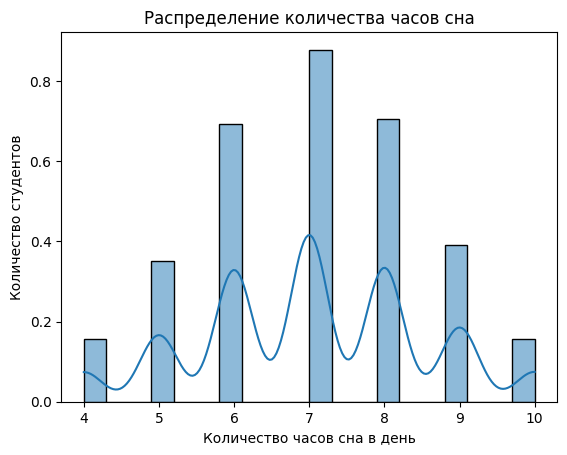

NormaltestResult(statistic=np.float64(129.32306755775704), pvalue=np.float64(8.276613754907294e-29))


In [119]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


sns.histplot(df['Sleep_Hours'], bins = 20, kde = True, stat = 'density')

plt.title('Распределение количества часов сна')
plt.xlabel('Количество часов сна в день')
plt.ylabel('Количество студентов')
plt.show()

print(stats.normaltest(df['Sleep_Hours']))

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

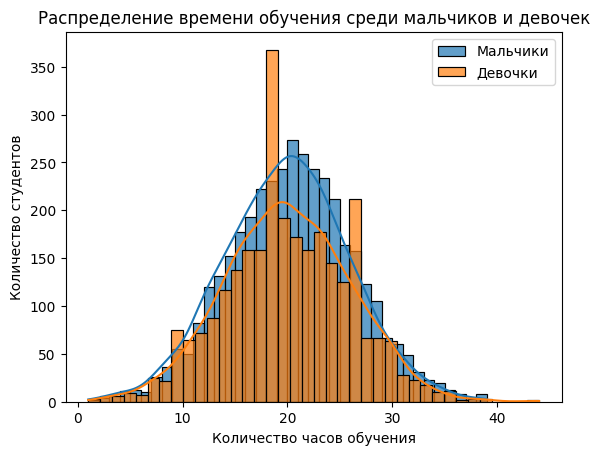

In [120]:
sns.histplot(data = df[df['Gender'] == 'Male'], x = 'Hours_Studied', label = 'Мальчики', kde = True, alpha = 0.7)
sns.histplot(data = df[df['Gender'] == 'Female'], x = 'Hours_Studied', label = 'Девочки', kde = True, alpha = 0.7)
plt.title('Распределение времени обучения среди мальчиков и девочек')
plt.xlabel('Количество часов обучения')
plt.ylabel('Количество студентов')
plt.legend()
plt.show()

3. Как зависит результат конечного экзамена от результата первого экзамена

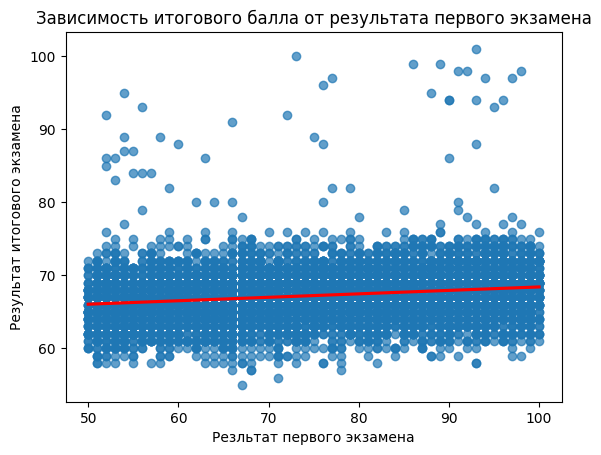

Корреляция: 0.17507908702291095


In [121]:
plt.scatter(df['Previous_Scores'], df['Exam_Score'], alpha = 0.7)
sns.regplot(data = df, x = 'Previous_Scores', y = 'Exam_Score', scatter = False, line_kws = {'color': 'red'})

plt.title('Зависимость итогового балла от результата первого экзамена')
plt.xlabel('Резльтат первого экзамена')
plt.ylabel('Результат итогового экзамена')
plt.show()

print(f"Корреляция: {df['Previous_Scores'].corr(df['Exam_Score'])}")

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

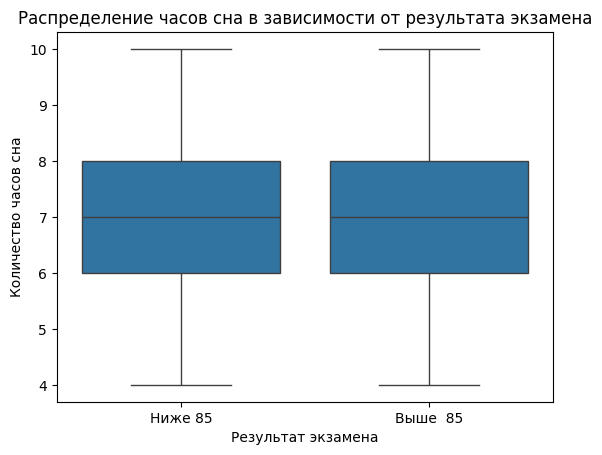

In [122]:
sns.boxplot(data = df, x = pd.cut(df['Exam_Score'], bins = [-float('inf'), 85, float('inf')], labels = ['Ниже 85', 'Выше  85']), y = 'Sleep_Hours')
plt.title('Распределение часов сна в зависимости от результата экзамена')
plt.xlabel('Результат экзамена')
plt.ylabel('Количество часов сна')
plt.show()

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

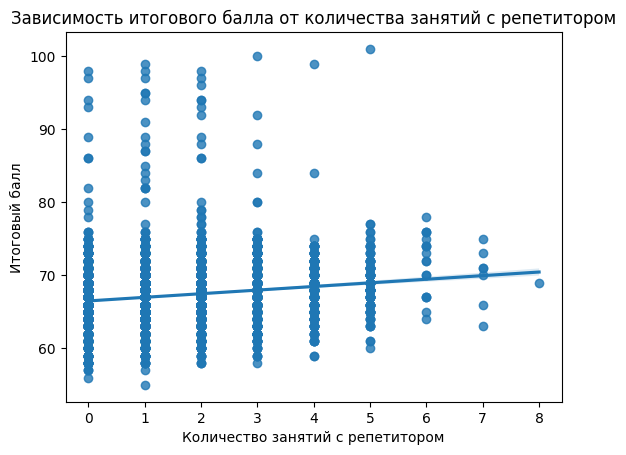

Корреляция: 0.15652518539225324


In [123]:
sns.regplot(data = df, x = 'Tutoring_Sessions', y = 'Exam_Score')
plt.title('Зависимость итогового балла от количества занятий с репетитором')
plt.xlabel('Количество занятий с репетитором')
plt.ylabel('Итоговый балл')
plt.show()
print(f"Корреляция: {df['Tutoring_Sessions'].corr(df['Exam_Score'])}")

6. Как физическая активность влияет на успеваемость?

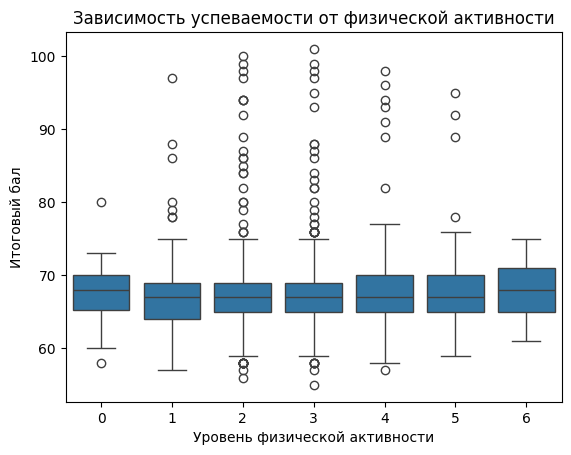

In [124]:
sns.boxplot(data = df, x = 'Physical_Activity', y = 'Exam_Score')
plt.title('Зависимость успеваемости от физической активности')
plt.xlabel('Уровень физической активности')
plt.ylabel('Итоговый бал')
plt.show()

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

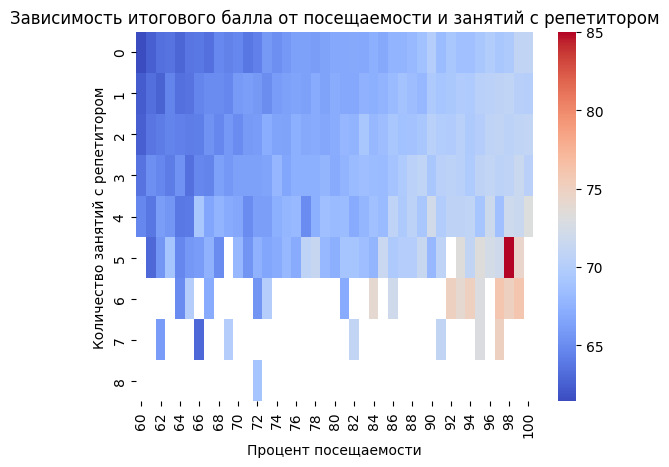

In [125]:
heatmap_data = df.pivot_table(index = 'Tutoring_Sessions', columns = 'Attendance', values = 'Exam_Score', aggfunc = 'mean')
sns.heatmap(heatmap_data, cmap = 'coolwarm')
plt.title('Зависимость итогового балла от посещаемости и занятий с репетитором')
plt.xlabel('Процент посещаемости')
plt.ylabel('Количество занятий с репетитором')
plt.show()